# Pricing American Options

Whereas a European option can be exercised only at a fixed date, an American option can be exercised any time up to its expiration, thus, the value of an American option is the value achieved by exercising optimally.
The problem is to solve the following optimization problem:
$ sup_{\tau \in \Tau} \mathbb{E}[U(\tau)]$, where $\tau$ representa a stopping time taking value in $[0,T]$ and $U$ represents the discounted payoff from exercise at time t.

We begin by pricing an American Put with interest rate $r$ and divident yield $q$ constant and positive s.t. r > q, depending on only one asset which follows the dynamics of black-Scholes model, using the Longstaff–Schwartz method, a standard approach in the literature.

Therefore, consider a version of black-Scholes model in which the underlying asset has dividend yield $q$, then the risk-neutral dynamics of the asset is given by 
$$
\frac{dS_t}{S_t} = ( r - q ) dt + \sigma dW_t
$$

More specifically in the present simulation we are considering a bermudan option where every discretized time point is a possible exercise date.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from code_utils import *

In [2]:
K = 100 # Strike price
sigma = 0.3 # Volatility 
r = 0.05  # Risk-free rate
q = 0 # Dividend yield
mu = r - q  # Drift 
T = 0.2  # Maturity 
dt = 0.004  # Time step 
N = int(T / dt)  # Number of steps 
npaths_train= 10**5 # Number of paths for estimating the coefficients of the regression 
npaths_pricing = 10**6 # Number of paths for estimating the price of the option 
max_deg = 4 # Degree of the polynomial basis for regression
seed = 42 # Random seed for reproducibility

# Computing the intrinsic value at time t discounted to time 0 when necessary
real_prices = np.array([40.00000000, 39.00000000, 38.00000000, 37.00000000, 36.00000000, 35.00000000, 34.00000000, 33.00000000, 32.00000000, 31.00000000,
						30.00000000, 29.00000000, 28.00000000, 27.00000000, 26.00000000, 25.00000000, 24.00000000, 23.00000000, 22.00000000, 21.00000000,
						20.00070685, 19.01347004, 18.04313091, 17.09109638, 16.15883366, 15.24783858, 14.35960625, 13.49560169, 12.65723381, 11.84582143,
						11.06257234, 10.30856320, 9.58471980, 8.89180771, 8.23041673, 7.60094690, 7.00361025, 6.43844700, 5.90532237, 5.40390521,
						4.93370425, 4.49410547, 4.08432251, 3.70344748, 3.35050142, 3.02435964, 2.72386986, 2.44779995, 2.19486933, 1.96380311,
						1.75326609, 1.56197956, 1.38862261, 1.23195119, 1.09070376, 0.96370545, 0.84978944, 0.74786820, 0.65689777, 0.57588855,
						0.50392803, 0.44013960, 0.38373063, 0.33395543, 0.29012326, 0.25161274, 0.21784490, 0.18829301, 0.16248633, 0.13999277,
						0.12042199, 0.10342780, 0.08869869, 0.07595400, 0.06494518, 0.05545341, 0.04728321, 0.04026147, 0.03423616, 0.02907429,0.02465918 ])


# Paths simulation 
train_set = simulate_gbm(mu, sigma, T, dt, npaths_train, seed=seed)
test_set = simulate_gbm( mu, sigma, T, dt, npaths_pricing, seed = seed + 1)

# Applying transformation
train_log = transformation(train_set)
test_log = transformation(test_set)

# Discount factors for each time step
discount_factors = np.exp(-r * np.arange(0, N + 1) * dt) 

# Precomputing the basis for the regression since after transformation the input doesn't depend on S0
basis_train = np.ones((N-1,npaths_train, max_deg + 1))	
basis_pricing = np.ones((N-1, npaths_pricing, max_deg + 1))
for d in range(1, max_deg + 1):
	basis_train[:, :, d] = train_log[1:N,:] * basis_train[:, :, d-1]
	basis_pricing[:, :, d] = test_log[1:N,:] * basis_pricing[:, :, d-1]

#coeffs_train_dict = {}
#contin_val_train_dict = {}
#value_train_dict = {}
prices = np.empty(81)
uncertainty = np.empty(81)

for S0 in np.arange(60,141):
	prices[S0-60], uncertainty[S0-60], _, _, _ = lower_bound_ls(K, S0, r, q, T, dt, sigma, train_set, test_set, train_log, test_log, discount_factors, npaths_train, npaths_pricing, max_deg, basis_train, basis_pricing, seed)
	# Printing the percentage error wrt the real price
	percentage_error = np.abs(prices[S0-60] - real_prices[S0 - 60]) / real_prices[S0 - 60] * 100
	print(f"S0= {S0}, Estimated Price: {prices[S0-60]:.5f}, Real Price: {real_prices[S0-60]:.5f}, Percentage Error: {percentage_error:.2f}%, Uncertainty: {uncertainty[S0-60]:.5f}")


S0= 60, Estimated Price: 40.00000, Real Price: 40.00000, Percentage Error: 0.00%, Uncertainty: 0.00019
S0= 61, Estimated Price: 39.00000, Real Price: 39.00000, Percentage Error: 0.00%, Uncertainty: 0.00019
S0= 62, Estimated Price: 38.00000, Real Price: 38.00000, Percentage Error: 0.00%, Uncertainty: 0.00020
S0= 63, Estimated Price: 37.00000, Real Price: 37.00000, Percentage Error: 0.00%, Uncertainty: 0.00020
S0= 64, Estimated Price: 36.00000, Real Price: 36.00000, Percentage Error: 0.00%, Uncertainty: 0.00021
S0= 65, Estimated Price: 35.00000, Real Price: 35.00000, Percentage Error: 0.00%, Uncertainty: 0.00021
S0= 66, Estimated Price: 34.00000, Real Price: 34.00000, Percentage Error: 0.00%, Uncertainty: 0.00021
S0= 67, Estimated Price: 33.00000, Real Price: 33.00000, Percentage Error: 0.00%, Uncertainty: 0.00021
S0= 68, Estimated Price: 32.00000, Real Price: 32.00000, Percentage Error: 0.00%, Uncertainty: 0.00021
S0= 69, Estimated Price: 31.00000, Real Price: 31.00000, Percentage Error

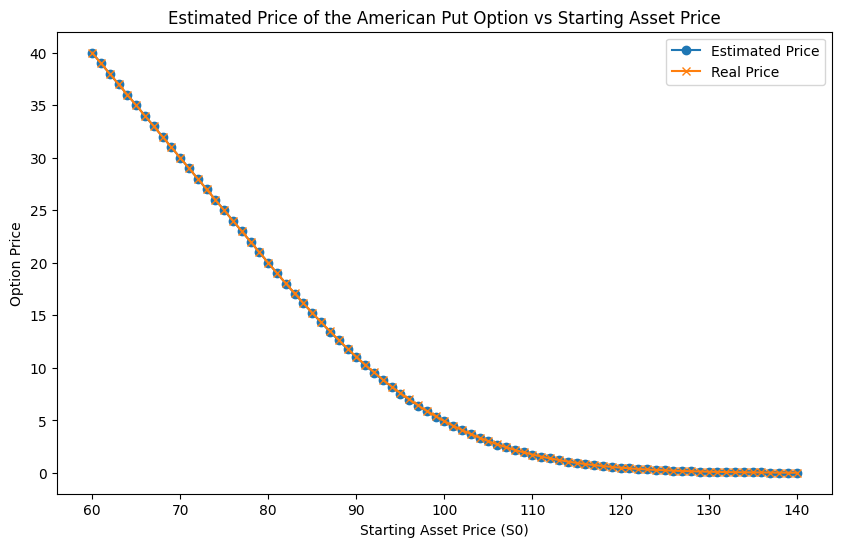

In [3]:
# Plot of the price of the option wrt the starting value of the asset
plt.figure(figsize = (10,6))
plt.plot(np.arange(60,141), prices, marker='o', label='Estimated Price')
plt.plot(np.arange(60,141), real_prices, marker='x', label='Real Price')
plt.title('Estimated Price of the American Put Option vs Starting Asset Price')
plt.xlabel('Starting Asset Price (S0)')
plt.ylabel('Option Price')
plt.legend()